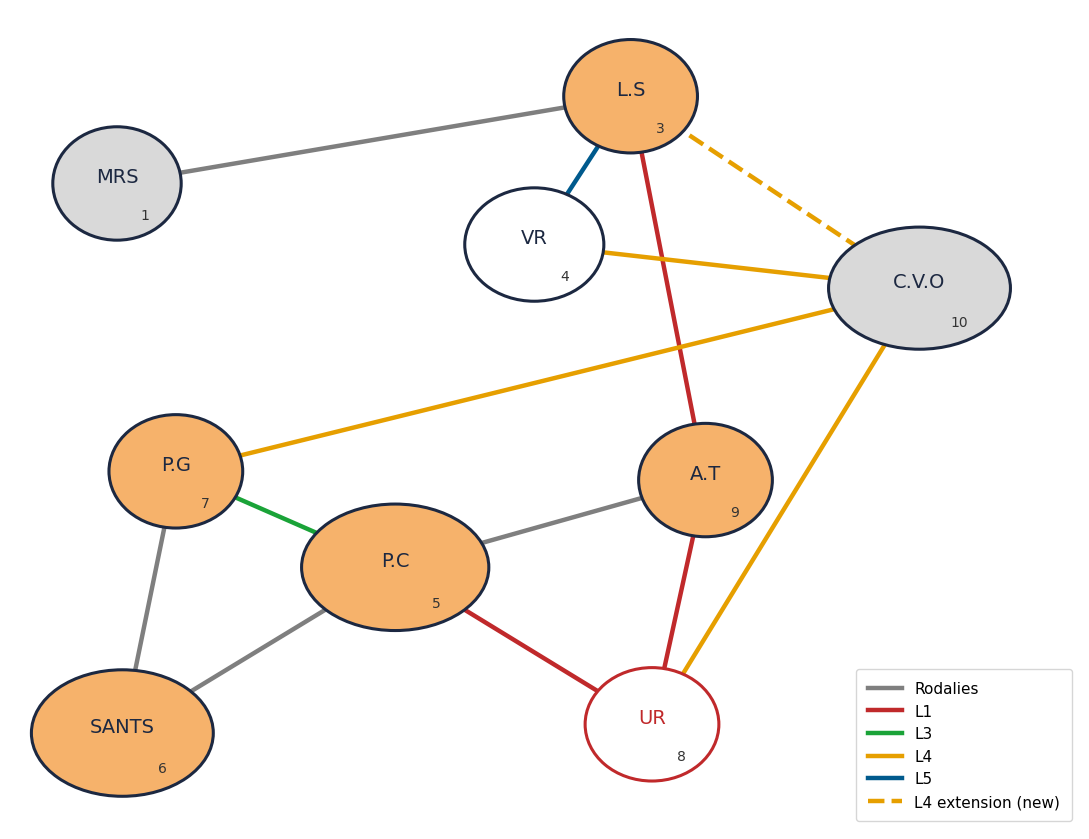

In [1]:
import matplotlib.lines as mlines
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import networkx as nx

# 1. Create the graph
G = nx.Graph()

# 2. Define nodes with exact coordinates, main label, sub-number, fill color, border color, and oval size (width, height)
nodes_data = {
    "MRS": {
        "pos": (1.0, 7.8),
        "num": "1",
        "fill": "#d9d9d9",
        "edge": "#1c2841",
        "size": (1.2, 1.3),
    },
    "L.S": {
        "pos": (5.8, 8.8),
        "num": "3",
        "fill": "#f6b26b",
        "edge": "#1c2841",
        "size": (1.25, 1.3),
    },
    "VR": {
        "pos": (4.9, 7.1),
        "num": "4",
        "fill": "#ffffff",
        "edge": "#1c2841",
        "size": (1.3, 1.3),
    },
    "C.V.O": {
        "pos": (8.5, 6.6),
        "num": "10",
        "fill": "#d9d9d9",
        "edge": "#1c2841",
        "size": (1.7, 1.4),
    },
    "P.G": {
        "pos": (1.55, 4.5),
        "num": "7",
        "fill": "#f6b26b",
        "edge": "#1c2841",
        "size": (1.25, 1.3),
    },
    "P.C": {
        "pos": (3.6, 3.4),
        "num": "5",
        "fill": "#f6b26b",
        "edge": "#1c2841",
        "size": (1.75, 1.45),
    },
    "A.T": {
        "pos": (6.5, 4.4),
        "num": "9",
        "fill": "#f6b26b",
        "edge": "#1c2841",
        "size": (1.25, 1.3),
    },
    "SANTS": {
        "pos": (1.05, 1.5),
        "num": "6",
        "fill": "#f6b26b",
        "edge": "#1c2841",
        "size": (1.7, 1.45),
    },
    "UR": {
        "pos": (6.0, 1.6),
        "num": "8",
        "fill": "#ffffff",
        "edge": "#c0292b",
        "size": (1.25, 1.3),
    },
}

for node, attr in nodes_data.items():
  G.add_node(node, **attr)

# 3. Define edges with line colors and styles matching the legend
edges_data = [
    # Rodalies (Grey)
    ("MRS", "L.S", {"color": "#7f7f7f", "style": "solid", "label": "Rodalies"}),
    ("P.G", "SANTS", {"color": "#7f7f7f", "style": "solid", "label": "Rodalies"}),
    ("P.C", "SANTS", {"color": "#7f7f7f", "style": "solid", "label": "Rodalies"}),
    ("P.C", "A.T", {"color": "#7f7f7f", "style": "solid", "label": "Rodalies"}),
    # L1 (Red)
    ("L.S", "A.T", {"color": "#c0292b", "style": "solid", "label": "L1"}),
    ("A.T", "UR", {"color": "#c0292b", "style": "solid", "label": "L1"}),
    ("P.C", "UR", {"color": "#c0292b", "style": "solid", "label": "L1"}),
    # L3 (Green)
    ("P.G", "P.C", {"color": "#1aa338", "style": "solid", "label": "L3"}),
    # L4 (Orange/Gold)
    ("VR", "C.V.O", {"color": "#e69f00", "style": "solid", "label": "L4"}),
    ("P.G", "C.V.O", {"color": "#e69f00", "style": "solid", "label": "L4"}),
    ("UR", "C.V.O", {"color": "#e69f00", "style": "solid", "label": "L4"}),
    # L5 (Blue)
    ("L.S", "VR", {"color": "#005a8d", "style": "solid", "label": "L5"}),
    # L4 extension (new) (Dashed Orange/Gold)
    (
        "L.S",
        "C.V.O",
        {"color": "#e69f00", "style": "dashed", "label": "L4 extension (new)"},
    ),
]

G.add_edges_from(edges_data)

# 4. Set up the figure
fig, ax = plt.subplots(figsize=(11, 8.5))
pos = {node: data["pos"] for node, data in nodes_data.items()}

# 5. Draw edges first so they sit behind the nodes
for u, v, d in G.edges(data=True):
  nx.draw_networkx_edges(
      G,
      pos,
      edgelist=[(u, v)],
      edge_color=d["color"],
      style=d["style"],
      width=3.2,
      ax=ax,
  )

# 6. Draw custom oval nodes and text labels
for node, data in nodes_data.items():
  x, y = data["pos"]
  w, h = data["size"]

  # Draw ellipse
  ellipse = patches.Ellipse(
      (x, y),
      width=w,
      height=h,
      facecolor=data["fill"],
      edgecolor=data["edge"],
      linewidth=2.2,
      zorder=3,
  )
  ax.add_patch(ellipse)

  # Main station label (centered)
  ax.text(
      x,
      y + 0.08,
      node,
      ha="center",
      va="center",
      fontsize=14,
      color="#1c2841" if node != "UR" else "#c0292b",
      zorder=4,
  )

  # Sub-number (offset toward bottom-right inside the oval)
  ax.text(
      x + w * 0.22,
      y - h * 0.28,
      data["num"],
      ha="center",
      va="center",
      fontsize=10,
      color="#333333",
      zorder=4,
  )

# 7. Create the custom legend in the bottom-right corner
legend_handles = [
    mlines.Line2D([], [], color="#7f7f7f", linewidth=3.2, label="Rodalies"),
    mlines.Line2D([], [], color="#c0292b", linewidth=3.2, label="L1"),
    mlines.Line2D([], [], color="#1aa338", linewidth=3.2, label="L3"),
    mlines.Line2D([], [], color="#e69f00", linewidth=3.2, label="L4"),
    mlines.Line2D([], [], color="#005a8d", linewidth=3.2, label="L5"),
    mlines.Line2D(
        [],
        [],
        color="#e69f00",
        linewidth=3.2,
        linestyle="--",
        label="L4 extension (new)",
    ),
]

ax.legend(
    handles=legend_handles,
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc",
    fontsize=11,
    handlelength=2.2,
    borderpad=0.8,
)

# 8. Adjust plot bounds and hide axes
ax.set_xlim(0.0, 10.0)
ax.set_ylim(0.4, 9.8)
ax.axis("off")
plt.tight_layout()
plt.show()

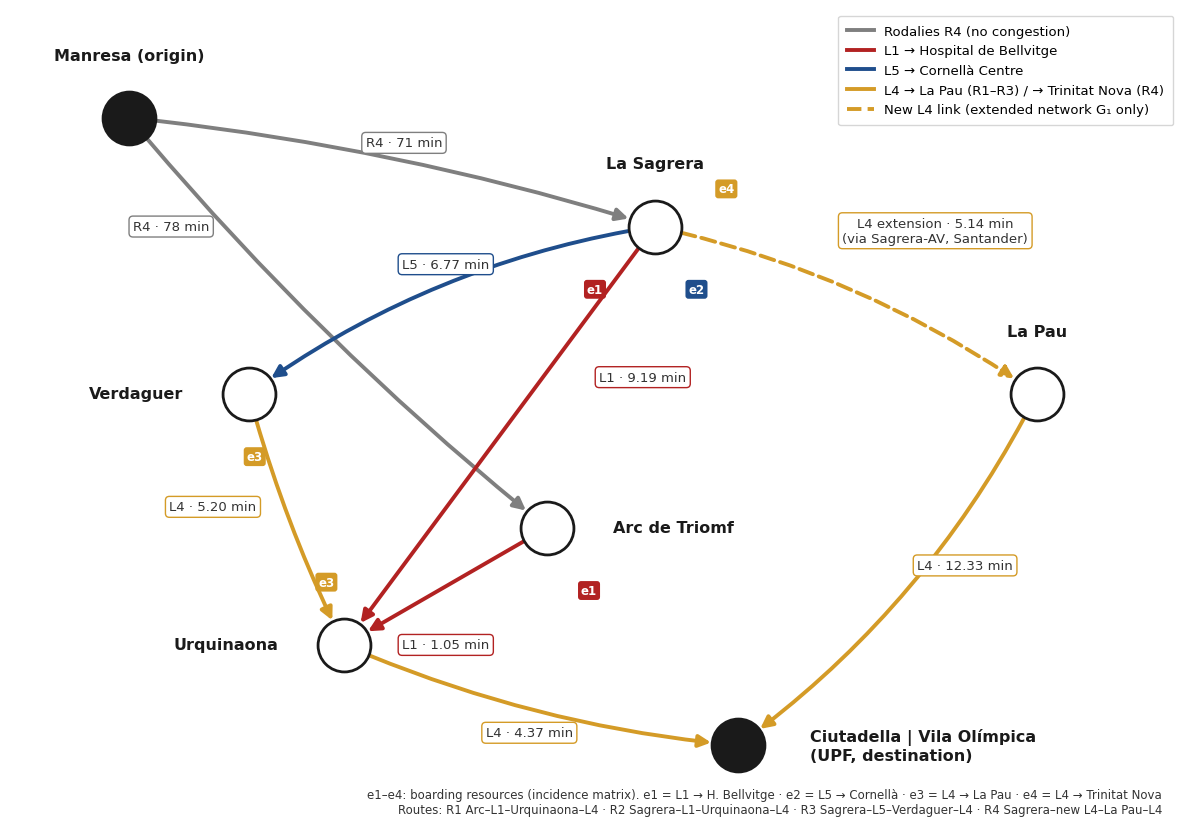

In [2]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import networkx as nx

# 1. Create a Directed Graph (DiGraph)
G = nx.DiGraph()

# 2. Define nodes with positions, colors, and label offsets
nodes_data = {
    "Manresa": {
        "pos": (1.2, 8.5),
        "color": "#1a1a1a",
        "label": "Manresa (origin)",
        "l_pos": (1.2, 9.25),
        "ha": "center",
    },
    "La Sagrera": {
        "pos": (5.6, 7.2),
        "color": "white",
        "label": "La Sagrera",
        "l_pos": (5.6, 7.95),
        "ha": "center",
    },
    "Verdaguer": {
        "pos": (2.2, 5.2),
        "color": "white",
        "label": "Verdaguer",
        "l_pos": (1.65, 5.2),
        "ha": "right",
    },
    "Arc de Triomf": {
        "pos": (4.7, 3.6),
        "color": "white",
        "label": "Arc de Triomf",
        "l_pos": (5.25, 3.6),
        "ha": "left",
    },
    "Urquinaona": {
        "pos": (3.0, 2.2),
        "color": "white",
        "label": "Urquinaona",
        "l_pos": (2.45, 2.2),
        "ha": "right",
    },
    "La Pau": {
        "pos": (8.8, 5.2),
        "color": "white",
        "label": "La Pau",
        "l_pos": (8.8, 5.95),
        "ha": "center",
    },
    "Ciutadella": {
        "pos": (6.3, 1.0),
        "color": "#1a1a1a",
        "label": "Ciutadella | Vila Olímpica\n(UPF, destination)",
        "l_pos": (6.9, 1.0),
        "ha": "left",
    },
}

for node, attr in nodes_data.items():
  G.add_node(node, **attr)

# 3. Define directed edges with travel times, colors, curve radii, and label positions
edges_data = [
    (
        "Manresa",
        "La Sagrera",
        {
            "weight": 71.0,
            "color": "#7f7f7f",
            "style": "solid",
            "rad": -0.05,
            "text": "R4 · 71 min",
            "t_pos": (3.5, 8.2),
        },
    ),
    (
        "Manresa",
        "Arc de Triomf",
        {
            "weight": 78.0,
            "color": "#7f7f7f",
            "style": "solid",
            "rad": 0.05,
            "text": "R4 · 78 min",
            "t_pos": (1.55, 7.2),
        },
    ),
    (
        "La Sagrera",
        "Verdaguer",
        {
            "weight": 6.77,
            "color": "#1f4e8c",
            "style": "solid",
            "rad": 0.12,
            "text": "L5 · 6.77 min",
            "t_pos": (3.85, 6.75),
        },
    ),
    (
        "La Sagrera",
        "Urquinaona",
        {
            "weight": 9.19,
            "color": "#b22222",
            "style": "solid",
            "rad": 0.0,
            "text": "L1 · 9.19 min",
            "t_pos": (5.5, 5.4),
        },
    ),
    (
        "La Sagrera",
        "La Pau",
        {
            "weight": 5.14,
            "color": "#d49b27",
            "style": "dashed",
            "rad": -0.1,
            "text": "L4 extension · 5.14 min\n(via Sagrera-AV, Santander)",
            "t_pos": (7.95, 7.15),
        },
    ),
    (
        "Verdaguer",
        "Urquinaona",
        {
            "weight": 5.20,
            "color": "#d49b27",
            "style": "solid",
            "rad": 0.05,
            "text": "L4 · 5.20 min",
            "t_pos": (1.9, 3.85),
        },
    ),
    (
        "Arc de Triomf",
        "Urquinaona",
        {
            "weight": 1.05,
            "color": "#b22222",
            "style": "solid",
            "rad": 0.0,
            "text": "L1 · 1.05 min",
            "t_pos": (3.85, 2.2),
        },
    ),
    (
        "Urquinaona",
        "Ciutadella",
        {
            "weight": 4.37,
            "color": "#d49b27",
            "style": "solid",
            "rad": 0.08,
            "text": "L4 · 4.37 min",
            "t_pos": (4.55, 1.15),
        },
    ),
    (
        "La Pau",
        "Ciutadella",
        {
            "weight": 12.33,
            "color": "#d49b27",
            "style": "solid",
            "rad": -0.12,
            "text": "L4 · 12.33 min",
            "t_pos": (8.2, 3.15),
        },
    ),
]

G.add_edges_from(edges_data)

# 4. Set up figure
fig, ax = plt.subplots(figsize=(12, 8.5))
pos = {node: data["pos"] for node, data in nodes_data.items()}

# 5. Draw nodes
for node, data in nodes_data.items():
  nx.draw_networkx_nodes(
      G,
      pos,
      nodelist=[node],
      node_color=data["color"],
      edgecolors="#1a1a1a",
      linewidths=2.0,
      node_size=1450,
      ax=ax,
  )
  # Draw station names
  lx, ly = data["l_pos"]
  ax.text(
      lx,
      ly,
      data["label"],
      ha=data["ha"],
      va="center",
      fontsize=11.5,
      fontweight="bold",
      color="#1a1a1a",
  )

# 6. Draw directed curved/straight edges and travel-time boxes
for u, v, d in G.edges(data=True):
  nx.draw_networkx_edges(
      G,
      pos,
      edgelist=[(u, v)],
      edge_color=d["color"],
      style=d["style"],
      width=2.8,
      arrows=True,
      arrowstyle="-|>",
      arrowsize=18,
      node_size=1550,
      connectionstyle=f"arc3,rad={d['rad']}",
      ax=ax,
  )
  # Travel-time label pill
  tx, ty = d["t_pos"]
  ax.text(
      tx,
      ty,
      d["text"],
      ha="center",
      va="center",
      fontsize=9.5,
      color="#333333",
      bbox=dict(
          boxstyle="round,pad=0.3",
          facecolor="white",
          edgecolor=d["color"],
          linewidth=1.0,
      ),
  )

# 7. Draw boarding resource badges (e1–e4)
badges = [
    ("e1", (5.1, 6.45), "#b22222"),  # Near La Sagrera (L1)
    ("e2", (5.95, 6.45), "#1f4e8c"),  # Near La Sagrera (L5)
    ("e4", (6.2, 7.65), "#d49b27"),  # Near La Sagrera (L4 ext)
    ("e3", (2.25, 4.45), "#d49b27"),  # Below Verdaguer (L4)
    ("e3", (2.85, 2.95), "#d49b27"),  # Above Urquinaona (L4)
    ("e1", (5.05, 2.85), "#b22222"),  # Below Arc de Triomf (L1)
]

for label, (bx, by), color in badges:
  ax.text(
      bx,
      by,
      label,
      ha="center",
      va="center",
      fontsize=8.5,
      fontweight="bold",
      color="white",
      bbox=dict(
          boxstyle="round,pad=0.25", facecolor=color, edgecolor="none"
      ),
  )

# 8. Add Legend in top-right
legend_handles = [
    mlines.Line2D(
        [], [], color="#7f7f7f", lw=2.8, label="Rodalies R4 (no congestion)"
    ),
    mlines.Line2D(
        [], [], color="#b22222", lw=2.8, label="L1 → Hospital de Bellvitge"
    ),
    mlines.Line2D([], [], color="#1f4e8c", lw=2.8, label="L5 → Cornellà Centre"),
    mlines.Line2D(
        [],
        [],
        color="#d49b27",
        lw=2.8,
        label="L4 → La Pau (R1–R3) / → Trinitat Nova (R4)",
    ),
    mlines.Line2D(
        [],
        [],
        color="#d49b27",
        lw=2.8,
        linestyle="--",
        label="New L4 link (extended network G₁ only)",
    ),
]

ax.legend(
    handles=legend_handles,
    loc="upper right",
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc",
    fontsize=9.5,
    borderpad=0.7,
)

# 9. Add bottom footnote annotations
footnote = (
    "e1–e4: boarding resources (incidence matrix). e1 = L1 → H. Bellvitge · "
    "e2 = L5 → Cornellà · e3 = L4 → La Pau · e4 = L4 → Trinitat Nova\n"
    "Routes: R1 Arc–L1–Urquinaona–L4 · R2 Sagrera–L1–Urquinaona–L4 · "
    "R3 Sagrera–L5–Verdaguer–L4 · R4 Sagrera–new L4–La Pau–L4"
)
ax.text(
    9.85,
    0.15,
    footnote,
    ha="right",
    va="bottom",
    fontsize=8.5,
    color="#333333",
)

# 10. Final formatting
ax.set_xlim(0.2, 10.0)
ax.set_ylim(0.0, 9.8)
ax.axis("off")
plt.tight_layout()
plt.show()